In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [4]:
class BlogState(StateGraph):
    title: str
    outline: str
    content: str

In [5]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [6]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

In [7]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

In [8]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': 'Here\'s a detailed outline for a blog post on "The Rise of AI in India," designed to be comprehensive, engaging, and easy to follow.\n\n---\n\n## Blog Title Options:\n\n*   **The AI Awakening: Decoding India\'s Rapid Ascent in Artificial Intelligence**\n*   **India\'s AI Revolution: From Silicon Valley to Silicon Bharat**\n*   **Beyond the Hype: How India is Forging its Own AI Future**\n*   **The Next Tech Superpower? Charting the Rise of AI in India**\n\n---\n\n## Blog Outline: The AI Awakening: Decoding India\'s Rapid Ascent in Artificial Intelligence\n\n**Target Audience:** Tech enthusiasts, business leaders, policymakers, general public interested in India\'s digital transformation, students, and professionals in the AI/tech space.\n\n**Tone:** Informative, enthusiastic, balanced (acknowledging challenges), forward-looking.\n\n---\n\n### I. Introduction: Setting the Stage (Approx. 150-200 words)\n\n*   **A. The Global AI Buzz:**\n    *  

In [9]:
print(final_state['outline'])

Here's a detailed outline for a blog post on "The Rise of AI in India," designed to be comprehensive, engaging, and easy to follow.

---

## Blog Title Options:

*   **The AI Awakening: Decoding India's Rapid Ascent in Artificial Intelligence**
*   **India's AI Revolution: From Silicon Valley to Silicon Bharat**
*   **Beyond the Hype: How India is Forging its Own AI Future**
*   **The Next Tech Superpower? Charting the Rise of AI in India**

---

## Blog Outline: The AI Awakening: Decoding India's Rapid Ascent in Artificial Intelligence

**Target Audience:** Tech enthusiasts, business leaders, policymakers, general public interested in India's digital transformation, students, and professionals in the AI/tech space.

**Tone:** Informative, enthusiastic, balanced (acknowledging challenges), forward-looking.

---

### I. Introduction: Setting the Stage (Approx. 150-200 words)

*   **A. The Global AI Buzz:**
    *   Briefly mention the worldwide impact and transformative power of AI.
    

In [10]:
print(final_state['content'])

## The AI Awakening: Decoding India's Rapid Ascent in Artificial Intelligence

---

### I. Introduction: Setting the Stage

The world stands at the precipice of a technological revolution, and at its heart lies Artificial Intelligence. From powering personalized recommendations to enabling groundbreaking scientific discoveries, AI is not just a buzzword; it is the defining technology of our era, reshaping industries and societies globally. While nations worldwide grapple with AI's immense potential and complex challenges, one country is rapidly emerging as a formidable force in this landscape: India. From a nascent tech adopter just a few decades ago, India has transformed into a global innovation hub, now actively building and deploying AI solutions at an unprecedented pace. While the world discusses AI's future, India is actively building it, transforming industries and lives at an unprecedented pace.

This blog will delve into the multifaceted drivers behind India's burgeoning AI bo

In [12]:
print(final_state['title'])

Rise of AI in India


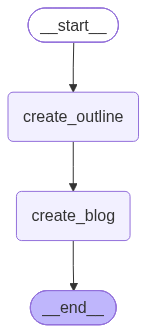

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())